1) Defining constants

In [1]:
# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 2.76      #(in m^2/s^2)

#l = 0.0100    # Arbitrary choice. (in m, knowing that η=0.000307 m, l must be << L)

2.76

2. Defining functions

In [2]:
# Function
f(h, l, v) = log(l/L) * ((h - c1)^2 / (2c2) - h) - 0.5 * (v/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, v) selon h
fprime(h, l, v) = log(l/L) * ((h - c1)/c2 - 1 + (v/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, v) selon h
fsecond(h, l, v) = log(l/L) * (1/c2 - 2 * (v/σ)^2 * log(l/L) * (l/L)^(-2h))

# Value of h_star
using LambertW
h_star(l, v) = (c1 + c2) - lambertw(2 * c2 * abs(log(l / L)) * ((l * v / σ)^2) * exp(2 * (c1 + c2) * abs(log(l / L)))) / (2 * abs(log(l / L)))
#h_star(l, v) = c1


h_star (generic function with 1 method)

3. Computation and plot

3.1. Display h* values

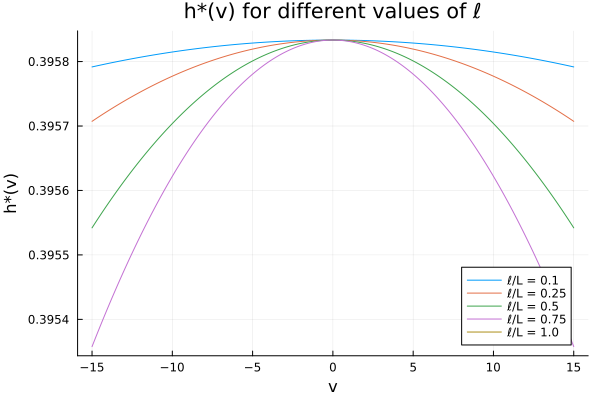

In [3]:
using Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for h*(v)
p = plot(title = "h*(v) for different values of ℓ",
         xlabel = "v",
         ylabel = "h*(v)",
         lw = 2)

# Loop over each l and plot the corresponding h*(v)
for l in l_values
    h_values = [h_star(l, v) for v in v_values]
    plot!(p, v_values, h_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Display the final plot
display(p)

3.2. Compute the pdf for one value

In [4]:
function compute_P_δlu_of_v(l, v; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, v), l, v) >= 0 || isnan(fsecond(h_star(l, v), l, v))
        return 0.0
    end

    prefactor = (1 / σ) * sqrt((-log(l/L)) / ((2π)^2 * c2)) * sqrt(2π / (-fsecond(h_star(l, v), l, v)))
    exponent = f(h_star(l, v), l, v)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_v (generic function with 1 method)

3.3. Plot the pdf and its log

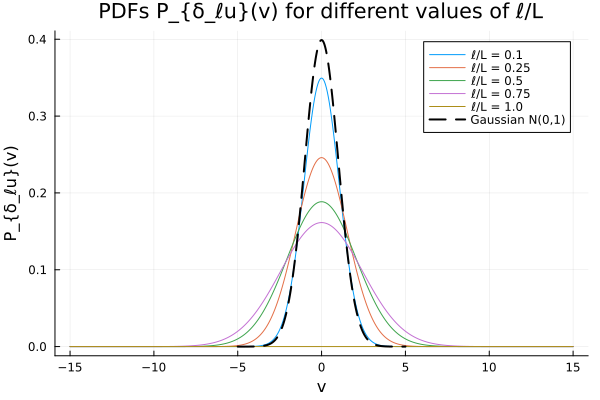

In [5]:
using Distributions, Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for P_{δlu}(v)
p1 = plot(title = "PDFs P_{δ_ℓu}(v) for different values of ℓ/L",
          xlabel = "v",
          ylabel = "P_{δ_ℓu}(v)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_v(l, v) for v in v_values]
    plot!(p1, v_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
v_gauss = -5:0.01:5
P_gauss = pdf.(gauss, v_gauss)
plot!(p1, v_gauss, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


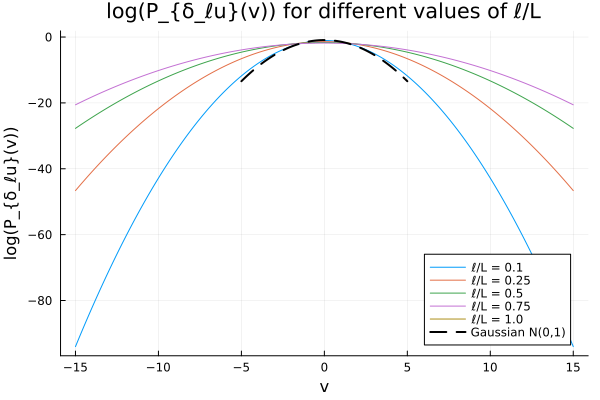

In [6]:
using Distributions, Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for log(P_{δlu}(v))
p1 = plot(title = "log(P_{δ_ℓu}(v)) for different values of ℓ/L",
          xlabel = "v",
          ylabel = "log(P_{δ_ℓu}(v))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(v))
for l in l_values
    P_values = [compute_P_δlu_of_v(l, v) for v in v_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_v = [v for (v, P) in zip(v_values, P_values) if P > 0]
    plot!(p1, valid_v, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
v_gauss = -5:0.01:5
P_gauss = pdf.(gauss, v_gauss)
logP_gauss = log.(P_gauss)
plot!(p1, v_gauss, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


4. Plotting the normalized PDF and its log

In [7]:
# Fonction pour calculer la PDF normalisée
function computeNormalizedPdf(l, nu; tol=1e-10, maxiter=100)
    # Calculer le facteur de normalisation
    normFactor = (L/l)^(c1 + 2*c2)
    
    # Convertir de nu à u
    u = nu / normFactor
    
    # Utiliser la fonction existante avec u
    return compute_P_δlu_of_v(l, u, tol=tol, maxiter=maxiter) 
end


computeNormalizedPdf (generic function with 1 method)

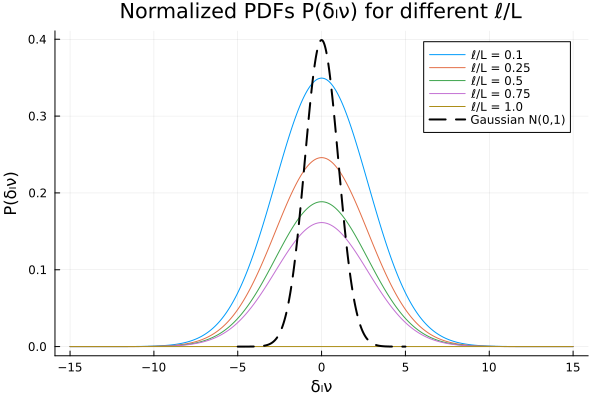

In [8]:

# Plot de la PDF normalisée
using Plots

# Définir les valeurs de l
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Définir les valeurs de nu (incrément normalisé)
nu_values = -15.0:0.01:15

# Créer le plot pour la PDF normalisée
p_norm = plot(title="Normalized PDFs P(δₗν) for different ℓ/L",
              xlabel="δₗν",
              ylabel="P(δₗν)",
              lw=2)

# Boucle sur chaque l et plot de la PDF normalisée correspondante
for l in l_values
    P_values = [computeNormalizedPdf(l, nu) for nu in nu_values]
    plot!(p_norm, nu_values, P_values, label="ℓ/L = $(round(l/L, digits=2))")
end

# Ajouter une Gaussienne standard pour référence
using Distributions
gauss = Normal(0, 1)
nu_gauss = -5.0:0.01:5
P_gauss = pdf.(gauss, nu_gauss)
plot!(p_norm, nu_gauss, P_gauss, label="Gaussian N(0,1)", lw=2, ls=:dash, color=:black)

display(p_norm)


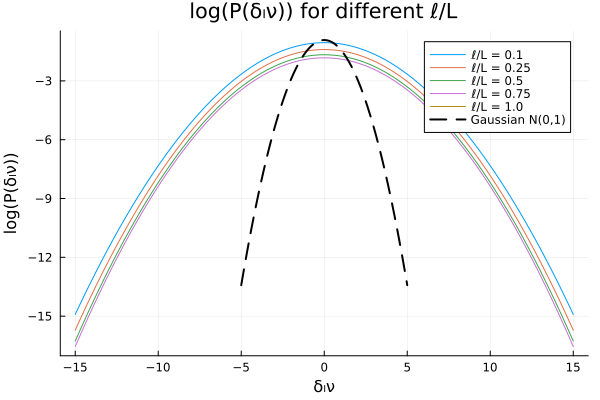

In [9]:
# Plot de log(P) pour la PDF normalisée
p_log_norm = plot(title="log(P(δₗν)) for different ℓ/L",
                  xlabel="δₗν",
                  ylabel="log(P(δₗν))",
                  lw=2)

# Boucle sur chaque l
for l in l_values
    P_values = [computeNormalizedPdf(l, nu) for nu in nu_values]
    log_P_values = [log(P) for P in P_values if P > 0]
    valid_nu = [nu for (nu, P) in zip(nu_values, P_values) if P > 0]
    plot!(p_log_norm, valid_nu, log_P_values, label="ℓ/L = $(round(l/L, digits=2))")
end

# Ajouter la Gaussienne pour référence
log_P_gauss = log.(P_gauss)
plot!(p_log_norm, nu_gauss, log_P_gauss, label="Gaussian N(0,1)", lw=2, ls=:dash, color=:black)

display(p_log_norm)
